In [1]:
import os

print(os.getcwd())

c:\B.TECH\DAML\DL\AI_based_Ocean_waste_plastic_detection_using_drone_image


In [2]:
import csv
from pathlib import Path
from collections import Counter

# Path to your dataset inside data/raw
DATASET_DIR = Path("data/raw/marine debris from drone.v1 robo flow")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def read_readme_files(dataset_dir: Path):
    print("=" * 65)
    print("1. READING DATASET README FILES")
    print("=" * 65)
    for readme_name in ["README.dataset.txt", "README.roboflow.txt"]:
        readme_path = dataset_dir / readme_name
        if readme_path.exists():
            print(f"\n--- {readme_name} ---")
            print(readme_path.read_text(encoding="utf-8", errors="ignore").strip())
            print("-" * 45)


def inspect_csv_in_split(dataset_dir: Path, split_name: str):
    split_dir = dataset_dir / split_name
    print("\n" + "=" * 65)
    print(f"2. INSPECTING CSV ANNOTATIONS IN: '{split_name}/'")
    print("=" * 65)

    if not split_dir.exists():
        print(f"  [WARNING] '{split_name}/' folder not found!")
        return Counter()

    image_files = {f.name for f in split_dir.iterdir() if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS}
    csv_files = [f for f in split_dir.iterdir() if f.is_file() and f.suffix.lower() == ".csv"]

    print(f"  Total image files on disk : {len(image_files)}")
    print(f"  CSV files found           : {[f.name for f in csv_files]}")

    if not csv_files:
        print("  [WARNING] No CSV file found in this split!")
        return Counter()

    csv_path = csv_files[0]
    class_counts = Counter()
    images_in_csv = set()
    total_rows = 0
    sample_rows = []
    missing_images_on_disk = set()

    with open(csv_path, mode="r", encoding="utf-8", errors="ignore", newline="") as f:
        reader = csv.reader(f)
        header = next(reader, None)
        print(f"  CSV Column Headers        : {header}")

        # Determine column indices if standard object detection CSV
        col_map = {col.strip().lower(): idx for idx, col in enumerate(header)} if header else {}
        filename_idx = col_map.get("filename", 0)
        class_idx = col_map.get("class", None)

        has_bbox_cols = all(k in col_map for k in ["xmin", "ymin", "xmax", "ymax"])
        print(f"  Has Bounding Box Columns? : {has_bbox_cols} (xmin, ymin, xmax, ymax)")

        for row in reader:
            if not row:
                continue
            total_rows += 1
            if len(sample_rows) < 5:
                sample_rows.append(row)

            fname = row[filename_idx].strip()
            images_in_csv.add(fname)
            if fname not in image_files:
                missing_images_on_disk.add(fname)

            if class_idx is not None and class_idx < len(row):
                class_counts[row[class_idx].strip()] += 1

    unannotated_images = image_files - images_in_csv

    print(f"  Total annotation rows     : {total_rows} (total bounding boxes in '{split_name}')")
    print(f"  Unique images in CSV      : {len(images_in_csv)}")
    print(f"  Images with 0 annotations : {len(unannotated_images)} (background/unlabeled images)")
    print(f"  CSV images missing on disk: {len(missing_images_on_disk)}")
    print(f"  Classes & Box Counts      : {dict(class_counts)}")

    print("\n  Sample first 5 rows from CSV:")
    print(f"    HEADER -> {header}")
    for i, srow in enumerate(sample_rows, start=1):
        print(f"    Row {i}  -> {srow}")

    return class_counts


def main():
    if not DATASET_DIR.exists():
        print(f"[ERROR] Dataset folder not found: {DATASET_DIR.resolve()}")
        return

    read_readme_files(DATASET_DIR)

    overall_classes = Counter()
    for split in ["train", "valid", "test"]:
        split_counts = inspect_csv_in_split(DATASET_DIR, split)
        overall_classes.update(split_counts)

    print("\n" + "=" * 65)
    print("3. OVERALL DATASET CLASS SUMMARY (ACROSS ALL SPLITS)")
    print("=" * 65)
    print(f"  Total Number of Classes : {len(overall_classes)}")
    print(f"  Class Names             : {list(overall_classes.keys())}")
    print(f"  Total Boxes per Class   : {dict(overall_classes)}")
    print("=" * 65)


if __name__ == "__main__":
    main()

1. READING DATASET README FILES

--- README.dataset.txt ---
# marine debris from drone > 2025-02-12 12:11am
https://universe.roboflow.com/marine-debris-7ap2f/marine-debris-from-drone

Provided by a Roboflow user
License: CC BY 4.0
---------------------------------------------

--- README.roboflow.txt ---
marine debris from drone - v1 2025-02-12 12:11am

This dataset was exported via roboflow.com on February 11, 2025 at 9:17 PM GMT

Roboflow is an end-to-end computer vision platform that helps you
* collaborate with your team on computer vision projects
* collect & organize images
* understand and search unstructured image data
* annotate, and create datasets
* export, train, and deploy computer vision models
* use active learning to improve your dataset over time

For state of the art Computer Vision training notebooks you can use with this dataset,
visit https://github.com/roboflow/notebooks

To find over 100k other datasets and pre-trained models, visit https://universe.roboflow.com


In [3]:
import os
import sys
import platform
import subprocess


def check_system_info():
    print("=" * 60)
    print("1. SYSTEM & PYTHON ENVIRONMENT")
    print("=" * 60)
    print(f"OS / Platform  : {platform.system()} {platform.release()} ({platform.version()})")
    print(f"Architecture   : {platform.machine()}")
    print(f"Processor      : {platform.processor()}")
    print(f"CPU Cores      : {os.cpu_count()} logical cores")
    print(f"Python Version : {sys.version.split()[0]}")
    print(f"Python Path    : {sys.executable}")

    # Check total RAM on Windows using wmic / powershell
    try:
        cmd = ["powershell", "-Command", "(Get-CimInstance Win32_ComputerSystem).TotalPhysicalMemory"]
        out = subprocess.check_output(cmd, text=True).strip()
        ram_gb = int(out) / (1024 ** 3)
        print(f"Total System RAM: {ram_gb:.2f} GB")
    except Exception as e:
        print(f"Total System RAM: Could not detect automatically ({e})")


def check_nvidia_gpu():
    print("\n" + "=" * 60)
    print("2. NVIDIA GPU & CUDA DRIVER CHECK (nvidia-smi)")
    print("=" * 60)
    try:
        out = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
            text=True,
            stderr=subprocess.STDOUT,
        ).strip()
        print(f"NVIDIA GPU Found : YES")
        for idx, line in enumerate(out.splitlines()):
            print(f"  GPU {idx}: {line}")
    except FileNotFoundError:
        print("NVIDIA GPU Found : NO ('nvidia-smi' command not found - likely integrated graphics/CPU only)")
    except Exception as e:
        print(f"NVIDIA GPU Check : Returned error ({e})")


def check_pytorch():
    print("\n" + "=" * 60)
    print("3. PYTORCH & GPU AVAILABILITY IN PYTHON")
    print("=" * 60)
    try:
        import torch
        print(f"PyTorch Installed       : YES (Version: {torch.__version__})")
        cuda_available = torch.cuda.is_available()
        print(f"CUDA Available in Torch : {cuda_available}")
        if cuda_available:
            print(f"CUDA Version (Torch)    : {torch.version.cuda}")
            print(f"GPU Device Name         : {torch.cuda.get_device_name(0)}")
        else:
            print("Note: PyTorch is currently running in CPU-only mode.")
    except ImportError:
        print("PyTorch Installed       : NO (Not installed in this Python environment yet)")
    print("=" * 60)


if __name__ == "__main__":
    check_system_info()
    check_nvidia_gpu()
    check_pytorch()

1. SYSTEM & PYTHON ENVIRONMENT
OS / Platform  : Windows 10 (10.0.26200)
Architecture   : AMD64
Processor      : Intel64 Family 6 Model 186 Stepping 2, GenuineIntel
CPU Cores      : 12 logical cores
Python Version : 3.11.9
Python Path    : c:\B.TECH\DAML\DL\AI_based_Ocean_waste_plastic_detection_using_drone_image\.venv\Scripts\python.exe
Total System RAM: 15.70 GB

2. NVIDIA GPU & CUDA DRIVER CHECK (nvidia-smi)
NVIDIA GPU Found : YES
  GPU 0: NVIDIA GeForce RTX 2050, 4096 MiB, 537.53

3. PYTORCH & GPU AVAILABILITY IN PYTHON
PyTorch Installed       : YES (Version: 2.5.1+cu121)
CUDA Available in Torch : True
CUDA Version (Torch)    : 12.1
GPU Device Name         : NVIDIA GeForce RTX 2050


In [4]:
import csv
from pathlib import Path
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt

# Paths
DATASET_DIR = Path("data/raw/marine debris from drone.v1 robo flow")
OUTPUT_DIR = Path("outputs/eda")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def check_images_and_csv(dataset_dir: Path, split_name: str):
    split_dir = dataset_dir / split_name
    image_files = sorted([f for f in split_dir.iterdir() if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS])

    resolutions = Counter()
    color_modes = Counter()
    corrupted_files = []
    zero_byte_files = []

    for img_path in image_files:
        if img_path.stat().st_size == 0:
            zero_byte_files.append(img_path.name)
            continue
        try:
            with Image.open(img_path) as img:
                resolutions[img.size] += 1  # (width, height)
                color_modes[img.mode] += 1  # e.g., 'RGB'
        except Exception as e:
            corrupted_files.append((img_path.name, str(e)))

    # Analyze the 5 binary columns in _classes.csv
    csv_path = split_dir / "_classes.csv"
    col_positive_counts = Counter()
    row_sum_counts = Counter()  # How many active '1' flags per image
    sample_by_col = {i: [] for i in range(1, 6)}

    if csv_path.exists():
        with open(csv_path, mode="r", encoding="utf-8", errors="ignore", newline="") as f:
            reader = csv.reader(f)
            _ = next(reader, None)  # skip corrupted header
            for row in reader:
                if len(row) < 6:
                    continue
                fname = row[0].strip()
                flags = []
                for col_idx in range(1, 6):
                    val = int(row[col_idx].strip()) if row[col_idx].strip().isdigit() else 0
                    flags.append(val)
                    if val == 1:
                        col_positive_counts[f"Col_{col_idx}"] += 1
                        if len(sample_by_col[col_idx]) < 3:
                            sample_by_col[col_idx].append((fname, flags))
                row_sum_counts[sum(flags)] += 1

    print(f"\n--- Split: '{split_name}/' ---")
    print(f"  Total Images Checked   : {len(image_files)}")
    print(f"  Zero-Byte Images       : {len(zero_byte_files)}")
    print(f"  Corrupted Images       : {len(corrupted_files)}")
    print(f"  Image Resolutions (WxH): {dict(resolutions)}")
    print(f"  Color Modes (Channels) : {dict(color_modes)}")
    print(f"  CSV Positive Counts    : {dict(sorted(col_positive_counts.items()))}")
    print(f"  Active Flags per Image : {dict(sorted(row_sum_counts.items()))} (key = number of '1's in row)")

    return {
        "count": len(image_files),
        "corrupted": corrupted_files,
        "resolutions": resolutions,
        "col_counts": col_positive_counts,
        "sample_by_col": sample_by_col,
    }


def save_split_chart(split_stats: dict, output_dir: Path):
    splits = ["train", "valid", "test"]
    counts = [split_stats[s]["count"] for s in splits]
    total = sum(counts)

    plt.figure(figsize=(8, 5))
    bars = plt.bar(splits, counts, color=["#1f77b4", "#ff7f0e", "#2ca02c"], edgecolor="black")
    plt.title("Dataset Split Distribution (Total: 6,354 Drone Images)", fontsize=13, fontweight="bold")
    plt.xlabel("Dataset Split", fontsize=11)
    plt.ylabel("Number of Images", fontsize=11)
    plt.ylim(0, max(counts) * 1.15)

    for bar, count in zip(bars, counts):
        pct = (count / total) * 100 if total > 0 else 0
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 80,
            f"{count}\n({pct:.1f}%)",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
        )

    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    chart_path = output_dir / "dataset_split_distribution.png"
    plt.savefig(chart_path, dpi=200)
    plt.close()
    print(f"\n[SAVED] Split distribution chart -> {chart_path}")


def save_sample_grid(train_dir: Path, sample_by_col: dict, output_dir: Path):
    # Pick up to 2 samples from each of the 5 CSV columns (total 10 images) in a 2x5 grid
    fig, axes = plt.subplots(2, 5, figsize=(16, 7))
    fig.suptitle("Sample Drone Images from 'train/' Across the 5 CSV Columns", fontsize=14, fontweight="bold")

    for col_idx in range(1, 6):
        samples = sample_by_col.get(col_idx, [])
        for row_idx in range(2):
            ax = axes[row_idx, col_idx - 1]
            if row_idx < len(samples):
                fname, flags = samples[row_idx]
                img_path = train_dir / fname
                if img_path.exists():
                    with Image.open(img_path) as img:
                        ax.imshow(img)
                    short_name = fname.split(".rf.")[0][:18]
                    ax.set_title(f"Col_{col_idx}=1 | {short_name}\nFlags: {flags}", fontsize=9)
            ax.axis("off")

    plt.tight_layout()
    grid_path = output_dir / "sample_drone_images.png"
    plt.savefig(grid_path, dpi=200)
    plt.close()
    print(f"[SAVED] Sample drone images grid -> {grid_path}")


def main():
    print("=" * 65)
    print("STAGE 4: EXPLORATORY DATA ANALYSIS (EDA) & INTEGRITY CHECK")
    print("=" * 65)

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    split_stats = {}

    for split in ["train", "valid", "test"]:
        split_stats[split] = check_images_and_csv(DATASET_DIR, split)

    save_split_chart(split_stats, OUTPUT_DIR)
    save_sample_grid(DATASET_DIR / "train", split_stats["train"]["sample_by_col"], OUTPUT_DIR)

    print("\n" + "=" * 65)
    print("EDA COMPLETE! Check the 'outputs/eda/' folder in VS Code.")
    print("=" * 65)


if __name__ == "__main__":
    main()

STAGE 4: EXPLORATORY DATA ANALYSIS (EDA) & INTEGRITY CHECK

--- Split: 'train/' ---
  Total Images Checked   : 5519
  Zero-Byte Images       : 0
  Corrupted Images       : 0
  Image Resolutions (WxH): {(640, 640): 5519}
  Color Modes (Channels) : {'RGB': 5519}
  CSV Positive Counts    : {'Col_1': 1517, 'Col_2': 1618, 'Col_3': 1053, 'Col_4': 1549, 'Col_5': 628}
  Active Flags per Image : {1: 5288, 2: 8, 3: 7, 4: 40, 5: 176} (key = number of '1's in row)

--- Split: 'valid/' ---
  Total Images Checked   : 572
  Zero-Byte Images       : 0
  Corrupted Images       : 0
  Image Resolutions (WxH): {(640, 640): 572}
  Color Modes (Channels) : {'RGB': 572}
  CSV Positive Counts    : {'Col_1': 145, 'Col_2': 153, 'Col_3': 106, 'Col_4': 150, 'Col_5': 98}
  Active Flags per Image : {1: 550, 3: 1, 4: 6, 5: 15} (key = number of '1's in row)

--- Split: 'test/' ---
  Total Images Checked   : 263
  Zero-Byte Images       : 0
  Corrupted Images       : 0
  Image Resolutions (WxH): {(640, 640): 263}
  Co

In [1]:
import csv
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

DATASET_DIR = Path("data/raw/marine debris from drone.v1 robo flow")
OUTPUT_DIR = Path("outputs/eda")


def get_valid_ocean_mask(img_bgr: np.ndarray) -> np.ndarray:
    """
    Uses FLOODFILL_FIXED_RANGE from the 4 corners to mask out solid gray/black
    rotation border triangles and erodes the mask to create a safe interior zone.
    """
    h, w = img_bgr.shape[:2]
    valid_mask = np.ones((h, w), dtype=np.uint8) * 255
    corners = [(2, 2), (w - 3, 2), (2, h - 3), (w - 3, h - 3)]

    flags = cv2.FLOODFILL_MASK_ONLY | cv2.FLOODFILL_FIXED_RANGE | (255 << 8)

    for cx, cy in corners:
        flood_mask = np.zeros((h + 2, w + 2), dtype=np.uint8)
        cv2.floodFill(
            img_bgr.copy(),
            flood_mask,
            seedPoint=(cx, cy),
            newVal=(255, 255, 255),
            loDiff=(10, 10, 10),
            upDiff=(10, 10, 10),
            flags=flags,
        )
        region = flood_mask[1:-1, 1:-1]
        area_ratio = np.count_nonzero(region) / float(h * w)
        touches_center = np.any(region[int(h * 0.32):int(h * 0.68), int(w * 0.32):int(w * 0.68)] > 0)

        if 0.0005 < area_ratio < 0.28 and not touches_center:
            valid_mask[region > 0] = 0

    # Erode valid region by 20 pixels along any detected rotation border
    if np.count_nonzero(valid_mask == 0) > 0:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (41, 41))
        valid_mask = cv2.erode(valid_mask, kernel, iterations=1)

    # Always ignore a 10-pixel safety margin around the outer frame edge
    margin = 10
    valid_mask[:margin, :] = 0
    valid_mask[-margin:, :] = 0
    valid_mask[:, :margin] = 0
    valid_mask[:, -margin:] = 0

    return valid_mask


def merge_overlapping_boxes(boxes: list, gap_px: float = 4.0) -> list:
    """
    Merges any overlapping, contained, or nearly-touching boxes into a single
    clean bounding box [xmin, ymin, xmax, ymax, max_score] so large containers
    or bottles are never split into multiple pieces.
    """
    if not boxes:
        return []

    merged = [list(b) for b in boxes]
    changed = True
    while changed:
        changed = False
        new_merged = []
        used = [False] * len(merged)
        for i in range(len(merged)):
            if used[i]:
                continue
            bx1, by1, bx2, by2, bscore = merged[i]
            for j in range(i + 1, len(merged)):
                if used[j]:
                    continue
                ox1, oy1, ox2, oy2, oscore = merged[j]
                # Check if boxes overlap or are within gap_px pixels of each other
                if not (bx2 + gap_px < ox1 or ox2 + gap_px < bx1 or by2 + gap_px < oy1 or oy2 + gap_px < by1):
                    bx1 = min(bx1, ox1)
                    by1 = min(by1, oy1)
                    bx2 = max(bx2, ox2)
                    by2 = max(by2, oy2)
                    bscore = max(bscore, oscore)
                    used[j] = True
                    changed = True
            new_merged.append([bx1, by1, bx2, by2, bscore])
        merged = new_merged

    return merged


def detect_plastic_boxes(img_bgr: np.ndarray) -> list:
    """
    Detects floating plastic waste while suppressing ocean wave ripples and border edges.
    Returns list of [xmin, ymin, xmax, ymax, score].
    """
    h, w = img_bgr.shape[:2]
    valid_mask = get_valid_ocean_mask(img_bgr)
    valid_bool = valid_mask > 0

    if np.count_nonzero(valid_bool) < 0.15 * h * w:
        valid_bool = np.ones((h, w), dtype=bool)

    img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    med_lab = np.median(img_lab[valid_bool], axis=0)
    lab_filled = img_lab.copy()
    lab_filled[~valid_bool] = med_lab

    # Local ocean background smoothing
    bg_lab = cv2.GaussianBlur(lab_filled, (51, 51), 18)
    diff_lab = lab_filled - bg_lab

    # 1. Chromaticity contrast (colored plastic)
    chroma_dist = np.sqrt(diff_lab[:, :, 1] ** 2 + diff_lab[:, :, 2] ** 2)

    # 2. Morphological Top-Hat (27x27) for bright plastic bottles, masks, containers, caps
    se_tophat = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (27, 27))
    tophat_l = cv2.morphologyEx(lab_filled[:, :, 0], cv2.MORPH_TOPHAT, se_tophat)

    # 3. Dark-object contrast on medium/bright water
    blackhat_l = np.zeros_like(tophat_l)
    if med_lab[0] > 60:
        blackhat_l = cv2.morphologyEx(lab_filled[:, :, 0], cv2.MORPH_BLACKHAT, se_tophat) * 0.75

    saliency = 1.8 * chroma_dist + 1.25 * tophat_l + blackhat_l
    saliency[~valid_bool] = 0.0

    s_valid = saliency[valid_bool]
    med_s = float(np.median(s_valid))
    mad_s = float(np.median(np.abs(s_valid - med_s))) + 1e-5
    robust_std = 1.4826 * mad_s

    thresh_val = max(med_s + 6.5 * robust_std, 28.0)
    binary = ((saliency >= thresh_val) & valid_bool).astype(np.uint8) * 255

    k_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    k_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, k_open)
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, k_close)

    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    candidate_boxes = []

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area < 14 or area > 0.12 * (h * w):
            continue

        x, y, bw, bh = cv2.boundingRect(cnt)
        aspect = max(bw, bh) / float(min(bw, bh) + 1e-5)
        if aspect > 5.2:
            continue

        # Reject any box that touches the invalid border mask
        box_mask_crop = valid_mask[y:y + bh, x:x + bw]
        if np.mean(box_mask_crop > 0) < 0.95:
            continue

        roi_sal = saliency[y:y + bh, x:x + bw]
        peak_score = float(np.max(roi_sal))
        mean_score = float(np.mean(roi_sal))

        if peak_score < thresh_val * 1.25:
            continue

        pad = 3
        x1 = max(0, x - pad)
        y1 = max(0, y - pad)
        x2 = min(w - 1, x + bw + pad)
        y2 = min(h - 1, y + bh + pad)
        candidate_boxes.append([x1, y1, x2, y2, peak_score * 0.7 + mean_score * 0.3])

    merged = merge_overlapping_boxes(candidate_boxes, gap_px=4.0)

    if merged:
        max_score = max(b[4] for b in merged)
        merged = [b for b in merged if b[4] >= max(max_score * 0.32, 32.0)]
        merged = sorted(merged, key=lambda b: b[4], reverse=True)[:18]

    return merged


def select_10_unique_samples(train_dir: Path) -> list:
    csv_path = train_dir / "_classes.csv"
    sample_by_col = {i: [] for i in range(1, 6)}
    seen_files = set()

    with open(csv_path, mode="r", encoding="utf-8", errors="ignore", newline="") as f:
        reader = csv.reader(f)
        _ = next(reader, None)
        for row in reader:
            if len(row) < 6:
                continue
            fname = row[0].strip()
            if fname in seen_files:
                continue
            for col_idx in range(1, 6):
                val = int(row[col_idx].strip()) if row[col_idx].strip().isdigit() else 0
                if val == 1 and len(sample_by_col[col_idx]) < 2:
                    sample_by_col[col_idx].append(fname)
                    seen_files.add(fname)
                    break

    selected = []
    for row_idx in range(2):
        for col_idx in range(1, 6):
            if row_idx < len(sample_by_col[col_idx]):
                selected.append((col_idx, sample_by_col[col_idx][row_idx]))
    return selected


def main():
    print("=" * 65)
    print("STAGE 5 (FINAL PILOT): TESTING CLEAN AUTO-LABELER ON 10 IMAGES")
    print("=" * 65)

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    train_dir = DATASET_DIR / "train"
    samples = select_10_unique_samples(train_dir)

    fig, axes = plt.subplots(2, 5, figsize=(18, 8))
    fig.suptitle("Final Verified YOLO Bounding Boxes (Green = plastic_waste)", fontsize=14, fontweight="bold")

    total_boxes = 0
    for idx, (col_idx, fname) in enumerate(samples):
        img_path = train_dir / fname
        img_bgr = cv2.imread(str(img_path))
        boxes = detect_plastic_boxes(img_bgr)
        total_boxes += len(boxes)

        vis_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        for (x1, y1, x2, y2, _) in boxes:
            cv2.rectangle(vis_rgb, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)

        r, c = divmod(idx, 5)
        ax = axes[r, c]
        ax.imshow(vis_rgb)
        short_name = fname.split(".rf.")[0][:16]
        ax.set_title(f"{short_name}\nDetected: {len(boxes)} plastic items", fontsize=9, fontweight="bold")
        ax.axis("off")
        print(f"  [{idx + 1:2d}/10] {short_name:<18} -> Detected {len(boxes):2d} plastic bounding boxes")

    plt.tight_layout()
    preview_path = OUTPUT_DIR / "autolabel_preview.png"
    plt.savefig(preview_path, dpi=200)
    plt.close()

    print("-" * 65)
    print(f"Total plastic objects detected across 10 unique sample images: {total_boxes}")
    print(f"[SAVED] Final Verified Preview -> {preview_path}")
    print("=" * 65)


if __name__ == "__main__":
    main()

STAGE 5 (FINAL PILOT): TESTING CLEAN AUTO-LABELER ON 10 IMAGES
  [ 1/10] DJI_0078_JPG_jpg   -> Detected  8 plastic bounding boxes
  [ 2/10] DJI_0704_JPG_jpg   -> Detected  6 plastic bounding boxes
  [ 3/10] frame2730_jpg      -> Detected 18 plastic bounding boxes
  [ 4/10] DJI_0403_JPG_jpg   -> Detected  3 plastic bounding boxes
  [ 5/10] frame1620_jpg      -> Detected  8 plastic bounding boxes
  [ 6/10] DJI_0081_JPG_jpg   -> Detected 11 plastic bounding boxes
  [ 7/10] DJI_0215_JPG_jpg   -> Detected  5 plastic bounding boxes
  [ 8/10] DJI_0046_JPG_jpg   -> Detected  4 plastic bounding boxes
  [ 9/10] DJI_0426_JPG_jpg   -> Detected  3 plastic bounding boxes
  [10/10] frame2760_jpg      -> Detected  8 plastic bounding boxes
-----------------------------------------------------------------
Total plastic objects detected across 10 unique sample images: 74
[SAVED] Final Verified Preview -> outputs\eda\autolabel_preview.png


In [7]:
from pathlib import Path

PROJECT = Path(
    r"C:\B.TECH\DAML\DL\PROJECT"
    r"\AI_based_Ocean_waste_plastic_detection_using_drone_image"
)

DATASET = PROJECT / "data" / "processed" / "yolo_dataset"
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

total_images = 0
total_labels = 0
total_boxes = 0
empty_labels = 0
invalid_lines = 0

print("=" * 60)
print("STAGE 5: YOLO DATASET VERIFICATION")
print("=" * 60)

for split in ["train", "valid", "test"]:
    image_dir = DATASET / split / "images"
    label_dir = DATASET / split / "labels"

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]
    labels = list(label_dir.glob("*.txt"))

    split_boxes = 0
    split_empty = 0
    split_invalid = 0

    for label in labels:
        content = label.read_text(encoding="utf-8").strip()

        if not content:
            split_empty += 1
            continue

        for line in content.splitlines():
            parts = line.split()

            try:
                valid = (
                    len(parts) == 5
                    and parts[0] == "0"
                    and all(
                        0.0 <= float(value) <= 1.0
                        for value in parts[1:]
                    )
                )
            except ValueError:
                valid = False

            if valid:
                split_boxes += 1
            else:
                split_invalid += 1

    total_images += len(images)
    total_labels += len(labels)
    total_boxes += split_boxes
    empty_labels += split_empty
    invalid_lines += split_invalid

    print(f"\n{split.upper()}")
    print(f"Images             : {len(images)}")
    print(f"Label files        : {len(labels)}")
    print(f"Bounding boxes     : {split_boxes}")
    print(f"Empty labels       : {split_empty}")
    print(f"Invalid label lines: {split_invalid}")

print("\n" + "=" * 60)
print("FINAL VERIFICATION SUMMARY")
print("=" * 60)
print(f"Total images       : {total_images}")
print(f"Total label files  : {total_labels}")
print(f"Total bounding boxes: {total_boxes}")
print(f"Empty labels       : {empty_labels}")
print(f"Invalid label lines: {invalid_lines}")
print("=" * 60)

STAGE 5: YOLO DATASET VERIFICATION

TRAIN
Images             : 5519
Label files        : 5519
Bounding boxes     : 31682
Empty labels       : 1
Invalid label lines: 0

VALID
Images             : 572
Label files        : 572
Bounding boxes     : 3189
Empty labels       : 0
Invalid label lines: 0

TEST
Images             : 263
Label files        : 263
Bounding boxes     : 1516
Empty labels       : 0
Invalid label lines: 0

FINAL VERIFICATION SUMMARY
Total images       : 6354
Total label files  : 6354
Total bounding boxes: 36387
Empty labels       : 1
Invalid label lines: 0


In [8]:
print("=" * 45)
print("OCEAN WASTE PLASTIC DETECTION")
print("YOLO DATASET SUMMARY")
print("=" * 45)

print("Total Images       : 6354")
print("Training Images    : 5519")
print("Validation Images  : 572")
print("Testing Images     : 263")
print("Total Label Files  : 6354")
print("Total Bounding Boxes: 36387")
print("Invalid Labels     : 0")
print("Dataset Status     : VERIFIED")
print("=" * 45)

OCEAN WASTE PLASTIC DETECTION
YOLO DATASET SUMMARY
Total Images       : 6354
Training Images    : 5519
Validation Images  : 572
Testing Images     : 263
Total Label Files  : 6354
Total Bounding Boxes: 36387
Invalid Labels     : 0
Dataset Status     : VERIFIED


In [9]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

PROCESSED_DIR = Path("data/processed/yolo_dataset")
OUTPUT_DIR = Path("outputs/eda")


def verify_split(split_name: str):
    img_dir = PROCESSED_DIR / split_name / "images"
    lbl_dir = PROCESSED_DIR / split_name / "labels"

    img_files = {f.stem: f for f in img_dir.glob("*.jpg")}
    lbl_files = {f.stem: f for f in lbl_dir.glob("*.txt")}

    missing_labels = set(img_files.keys()) - set(lbl_files.keys())
    orphan_labels = set(lbl_files.keys()) - set(img_files.keys())

    invalid_lines = []
    out_of_bounds_boxes = []
    box_counts_per_img = []
    box_widths_px = []
    box_heights_px = []

    for stem, lbl_path in sorted(lbl_files.items()):
        lines = [line.strip() for line in lbl_path.read_text(encoding="utf-8").splitlines() if line.strip()]
        box_counts_per_img.append(len(lines))

        for line_num, line in enumerate(lines, start=1):
            parts = line.split()
            if len(parts) != 5:
                invalid_lines.append((lbl_path.name, line_num, "Not 5 values"))
                continue
            try:
                cls_id = int(parts[0])
                xc, yc, bw, bh = map(float, parts[1:])
            except ValueError:
                invalid_lines.append((lbl_path.name, line_num, "Non-numeric value"))
                continue

            if cls_id != 0:
                invalid_lines.append((lbl_path.name, line_num, f"Unexpected class_id {cls_id}"))

            if not (0.0 <= xc <= 1.0 and 0.0 <= yc <= 1.0 and 0.0 < bw <= 1.0 and 0.0 < bh <= 1.0):
                out_of_bounds_boxes.append((lbl_path.name, line_num, (xc, yc, bw, bh)))
            else:
                box_widths_px.append(bw * 640.0)
                box_heights_px.append(bh * 640.0)

    print(f"\n--- Verification Report for '{split_name}/' ---")
    print(f"  Images found             : {len(img_files)}")
    print(f"  Label .txt files found   : {len(lbl_files)}")
    print(f"  Missing label files      : {len(missing_labels)}")
    print(f"  Orphan label files       : {len(orphan_labels)}")
    print(f"  Invalid format lines     : {len(invalid_lines)}")
    print(f"  Out-of-bounds boxes      : {len(out_of_bounds_boxes)}")
    print(f"  Valid boxes verified     : {len(box_widths_px)}")
    print(f"  Min / Max boxes in image : {min(box_counts_per_img)} / {max(box_counts_per_img)}")

    passed = (
        len(img_files) > 0
        and len(missing_labels) == 0
        and len(orphan_labels) == 0
        and len(invalid_lines) == 0
        and len(out_of_bounds_boxes) == 0
    )
    print(f"  STATUS                   : {'PASSED (100% VALID)' if passed else 'FAILED'}")

    return box_counts_per_img, box_widths_px, box_heights_px


def save_visual_verification_grid():
    """Reads .txt files from train, valid, and test and draws boxes on 9 sample images."""
    fig, axes = plt.subplots(3, 3, figsize=(15, 14))
    fig.suptitle("Stage 6: Visual Verification of Saved YOLO .txt Labels Across Splits", fontsize=14, fontweight="bold")

    splits = ["train", "valid", "test"]
    for row_idx, split in enumerate(splits):
        img_dir = PROCESSED_DIR / split / "images"
        lbl_dir = PROCESSED_DIR / split / "labels"
        sample_imgs = sorted(img_dir.glob("*.jpg"))[:3]

        for col_idx, img_path in enumerate(sample_imgs):
            lbl_path = lbl_dir / f"{img_path.stem}.txt"
            img_bgr = cv2.imread(str(img_path))
            vis_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            h, w = vis_rgb.shape[:2]

            lines = [l.strip() for l in lbl_path.read_text(encoding="utf-8").splitlines() if l.strip()]
            for line in lines:
                _, xc, yc, bw, bh = map(float, line.split())
                x1 = int((xc - bw / 2.0) * w)
                y1 = int((yc - bh / 2.0) * h)
                x2 = int((xc + bw / 2.0) * w)
                y2 = int((yc + bh / 2.0) * h)
                cv2.rectangle(vis_rgb, (x1, y1), (x2, y2), (0, 255, 0), 2)
                cv2.putText(vis_rgb, "plastic", (x1, max(14, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 0), 1)

            ax = axes[row_idx, col_idx]
            ax.imshow(vis_rgb)
            short_name = img_path.name.split(".rf.")[0][:18]
            ax.set_title(f"[{split.upper()}] {short_name}\n({len(lines)} boxes from .txt)", fontsize=10, fontweight="bold")
            ax.axis("off")

    plt.tight_layout()
    out_path = OUTPUT_DIR / "verified_yolo_labels.png"
    plt.savefig(out_path, dpi=200)
    plt.close()
    print(f"\n[SAVED] Visual label verification grid -> {out_path}")


def save_bbox_statistics_chart(all_counts, all_widths, all_heights):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot 1: Histogram of plastic objects per image
    bins = range(0, max(all_counts) + 2)
    axes[0].hist(all_counts, bins=bins, color="#2b83ba", edgecolor="black", align="left")
    axes[0].set_title("Distribution of Plastic Objects per Drone Image", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Number of Plastic Waste Objects Detected in Image", fontsize=10)
    axes[0].set_ylabel("Number of Images", fontsize=10)
    axes[0].grid(axis="y", linestyle="--", alpha=0.5)

    # Plot 2: Bounding box width vs height in pixels
    axes[1].hist(all_widths, bins=40, alpha=0.65, label="Box Width (px)", color="#fdae61", edgecolor="black")
    axes[1].hist(all_heights, bins=40, alpha=0.65, label="Box Height (px)", color="#abdda4", edgecolor="black")
    axes[1].set_title("Bounding Box Size Distribution (in Pixels on 640x640 Image)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Size in Pixels", fontsize=10)
    axes[1].set_ylabel("Number of Bounding Boxes", fontsize=10)
    axes[1].legend()
    axes[1].grid(axis="y", linestyle="--", alpha=0.5)

    plt.tight_layout()
    stat_path = OUTPUT_DIR / "bbox_statistics.png"
    plt.savefig(stat_path, dpi=200)
    plt.close()
    print(f"[SAVED] Bounding box statistics chart  -> {stat_path}")


def main():
    print("=" * 65)
    print("STAGE 6: YOLO ANNOTATION VERIFICATION & QUALITY CHECK")
    print("=" * 65)

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    all_counts, all_widths, all_heights = [], [], []

    for split in ["train", "valid", "test"]:
        c, w, h = verify_split(split)
        all_counts.extend(c)
        all_widths.extend(w)
        all_heights.extend(h)

    save_visual_verification_grid()
    save_bbox_statistics_chart(all_counts, all_widths, all_heights)

    print("\n" + "=" * 65)
    print("ANNOTATION VERIFICATION COMPLETE!")
    print("=" * 65)


if __name__ == "__main__":
    main()

STAGE 6: YOLO ANNOTATION VERIFICATION & QUALITY CHECK

--- Verification Report for 'train/' ---
  Images found             : 5519
  Label .txt files found   : 5519
  Missing label files      : 0
  Orphan label files       : 0
  Invalid format lines     : 0
  Out-of-bounds boxes      : 0
  Valid boxes verified     : 31682
  Min / Max boxes in image : 0 / 18
  STATUS                   : PASSED (100% VALID)

--- Verification Report for 'valid/' ---
  Images found             : 572
  Label .txt files found   : 572
  Missing label files      : 0
  Orphan label files       : 0
  Invalid format lines     : 0
  Out-of-bounds boxes      : 0
  Valid boxes verified     : 3189
  Min / Max boxes in image : 1 / 17
  STATUS                   : PASSED (100% VALID)

--- Verification Report for 'test/' ---
  Images found             : 263
  Label .txt files found   : 263
  Missing label files      : 0
  Orphan label files       : 0
  Invalid format lines     : 0
  Out-of-bounds boxes      : 0
  Valid bo

In [15]:
from pathlib import Path
import yaml

config_path = Path("configs/data.yaml")

with open(config_path, "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

dataset_path = Path(config["path"])

print("Configuration loaded successfully!")
print("Dataset path exists:", dataset_path.exists())

for split in ["train", "val", "test"]:
    image_dir = dataset_path / config[split]
    print(f"{split} images folder exists:", image_dir.exists())

print("Number of classes:", config["nc"])
print("Class names:", config["names"])

Configuration loaded successfully!
Dataset path exists: True
train images folder exists: True
val images folder exists: True
test images folder exists: True
Number of classes: 1
Class names: {0: 'plastic_waste'}


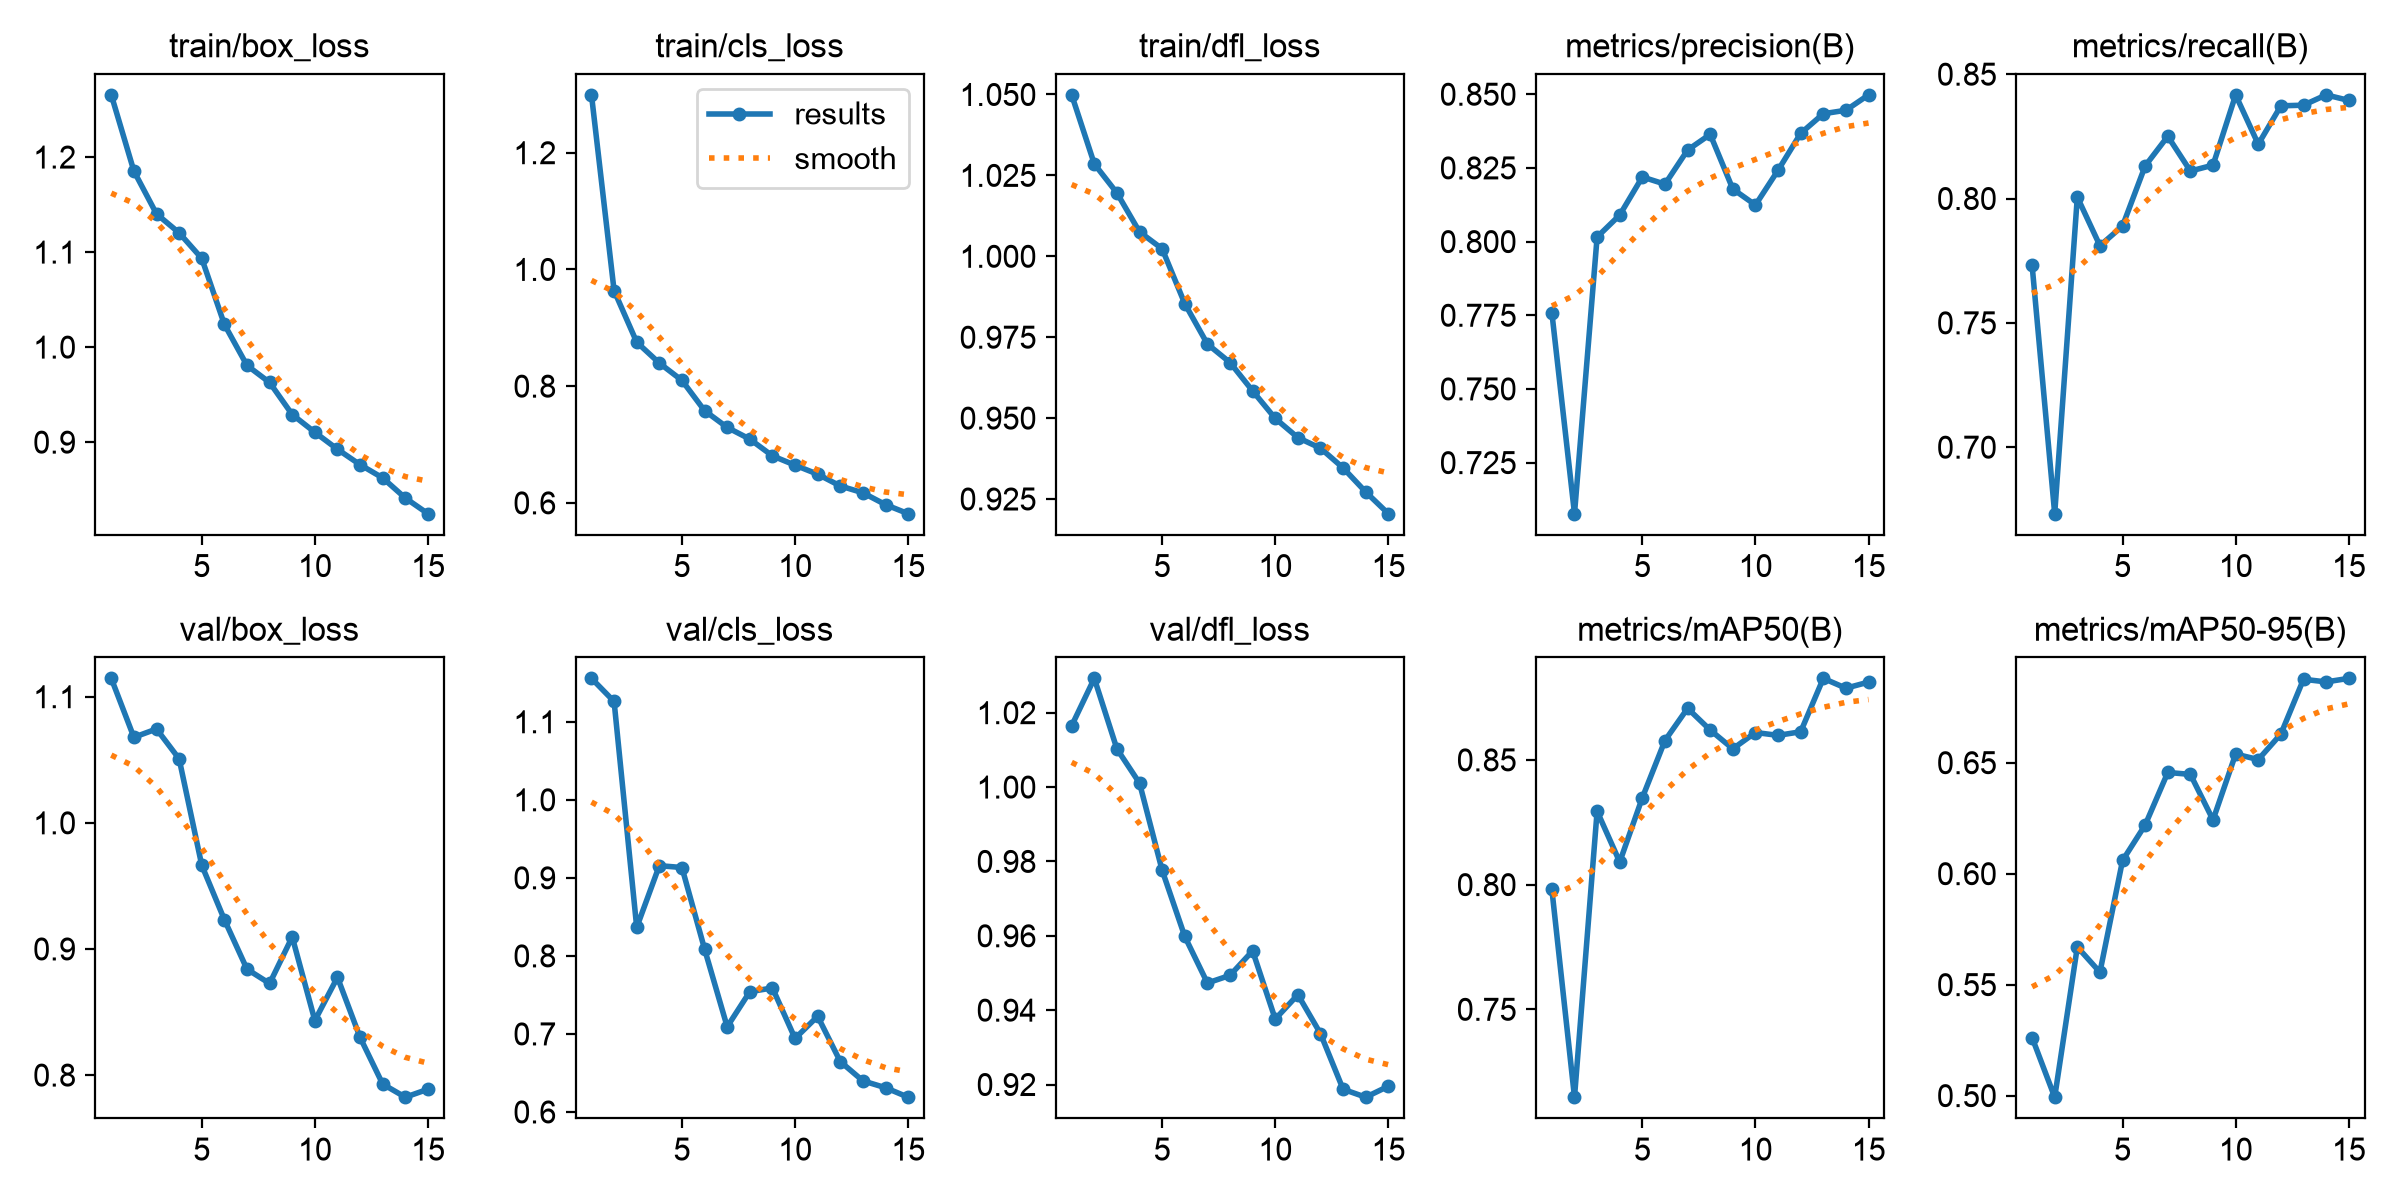

In [18]:
from pathlib import Path
from IPython.display import display, Image

results_img = (
    Path.cwd()
    / "outputs"
    / "models"
    / "ocean_plastic_yolov8n"
    / "results.png"
)

display(Image(filename=str(results_img), width=900))

In [19]:
from pathlib import Path
import pandas as pd

results_file = (
    Path.cwd()
    / "outputs"
    / "models"
    / "ocean_plastic_yolov8n"
    / "results.csv"
)

if results_file.exists():
    df = pd.read_csv(results_file)
    display(df.tail())
else:
    print("results.csv file nahi mili.")

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
10,11,830.304,0.89253,0.64911,0.94397,0.82420,0.82183,0.85983,0.65141,0.87752,0.72259,0.94416,0.000680,0.000680,0.000680
11,12,902.792,0.87627,0.62896,0.94070,0.83673,0.83728,0.86128,0.66291,0.82989,0.66460,0.93369,0.000548,0.000548,0.000548
12,13,974.771,0.86235,0.61727,0.93461,0.84338,0.83753,0.88268,0.68759,0.79287,0.63984,0.91873,0.000416,0.000416,0.000416
13,14,1047.080,0.84119,0.59698,0.92718,0.84456,0.84168,0.87875,0.68640,0.78248,0.63107,0.91659,0.000284,0.000284,0.000284
14,15,1119.210,0.82470,0.58146,0.92046,0.84978,0.83945,0.88119,0.68799,0.78880,0.61891,0.91954,0.000152,0.000152,0.000152


In [20]:
from pathlib import Path
import pandas as pd

file = Path.cwd() / "outputs" / "models" / "ocean_plastic_yolov8n" / "results.csv"
df = pd.read_csv(file)

print("Available metric columns:")
print(df.columns.tolist())

Available metric columns:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


In [21]:
df = pd.read_csv(file)

metrics = [
    "epoch",
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]

display(df[metrics].tail(5).round(4))

,epoch,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
10,11,0.8242,0.8218,0.8598,0.6514
11,12,0.8367,0.8373,0.8613,0.6629
12,13,0.8434,0.8375,0.8827,0.6876
13,14,0.8446,0.8417,0.8788,0.6864
14,15,0.8498,0.8394,0.8812,0.6880
